In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplfinance as mpf
from scipy.stats import ttest_ind
import seaborn as sns
from scipy.stats import shapiro
from scipy.stats import normaltest

In [96]:
# Load the dataset
# Load the Apple stock dataset into a DataFrame
df = pd.read_csv("Apple-Stock-Prices-1981-2023.csv")

# Display all column names to understand the dataset structure
print(df.columns)


# Display the data type of each column. This helps identify whether columns are numeric, text, or dates.
print(df.dtypes)


# Check for missing (null) values in each column
# This helps determine whether data cleaning is needed
print(df.isnull().sum())


# Calculate the percentage of missing values in each column
# Number of missing values ÷ total rows × 100
missing_percent = (
    df.isnull().sum() /
    len(df)
) * 100

# Display the percentage of missing values
print(missing_percent)


# Display all column names as a Python list. Useful for verifying exact spelling and spacing
print(df.columns.tolist())


# Check whether a 'Date' column exists in the dataset. This helps avoid KeyErrors later in the analysis
if 'Date' in df.columns:
    print("Date column found")
else:
    print("Date column not found")

# Examine the time-series properties of the dataset

# Convert the Date column to datetime format
# dayfirst=True interprets dates as DD/MM/YYYY
# Example: 13/01/1981 becomes 13 January 1981
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True
)

# Verify the conversion was successful
# Display the first few dates
print(df['Date'].head())

# Display the resulting data type. Should show datetime64[ns]
print(df['Date'].dtype)


# Convert Date column to datetime format again. (This line is actually unnecessary because the conversion has already been completed above)
df['Date'] = pd.to_datetime(df['Date'])


# Set the Date column as the DataFrame index. This is required for many time-series operations such as: resampling, moving averages, and trend analysis
df.set_index('Date', inplace=True)


# Display the first five rows of the dataset to confirm the Date column is now the index
print(df.head())

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'],
      dtype='str')
Date             str
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64
Date         0.0
Open         0.0
High         0.0
Low          0.0
Close        0.0
Adj Close    0.0
Volume       0.0
dtype: float64
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Date column found
0   1981-01-02
1   1981-01-05
2   1981-01-06
3   1981-01-07
4   1981-01-08
Name: Date, dtype: datetime64[us]
datetime64[us]
                Open      High       Low     Close  Adj Close    Volume
Date                                                                   
1981-01-02  0.154018  0.155134  0.154018  0.154018   0.119849  21660800
1981-01-05  0.151228  0.151228  0.150670  0.150670   0.117244  35728000
198

C:\Users\USER1\AppData\Local\Temp\ipykernel_8568\4206125946.py:62: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('Date', inplace=True)


The Apple stock dataset was imported using Pandas and inspected to understand its structure. Data types and missing values were examined to assess data quality. The Date column was converted to a datetime format and set as the DataFrame index, enabling time-series analysis techniques such as trend analysis, moving averages, resampling, and correlation analysis. Preliminary inspection confirmed that the dataset contained historical Apple stock information spanning 1981 to 2023 with the key financial variables Open, High, Low, Close, Adjusted Close, and Volume.

1981-01-02 00:00:00
2023-01-27 00:00:00
Date
1 days    8317
3 days    1927
4 days     265
2 days      95
5 days       2
Name: count, dtype: int64
None


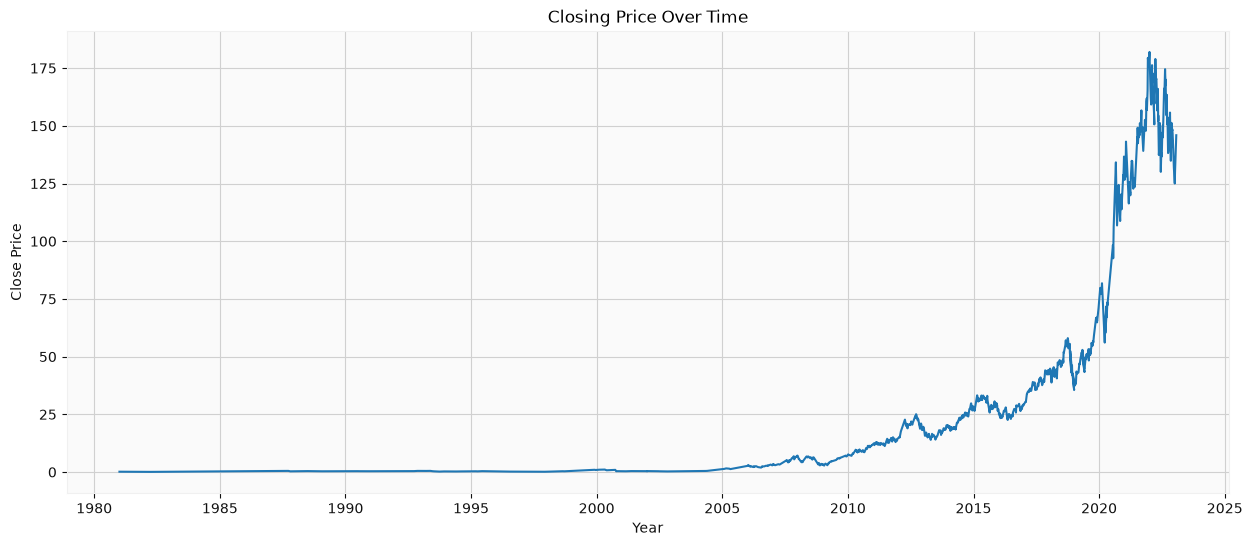

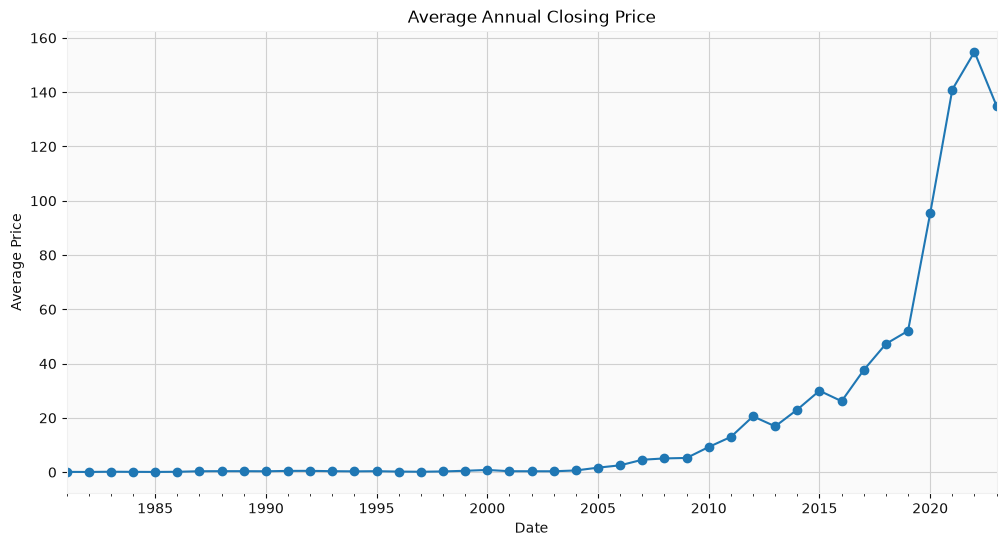

<module 'matplotlib.pyplot' from 'c:\\Users\\USER1\\AppData\\Local\\Python\\pythoncore-3.15-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

<Figure size 1500x600 with 0 Axes>

In [ ]:
# Check frequency of the data
# Display the earliest date in the dataset
# This identifies the starting point of the time series
print(df.index.min())

# Display the latest date in the dataset
# This identifies the ending point of the time series
print(df.index.max())

# Convert the Date index into a Series to perform calculations
# Calculate the difference between consecutive dates
# Count how often each time gap occurs
# Display the five most common intervals
print(
    df.index.to_series()
    .diff()
    .value_counts()
    .head()
)


# Automatically detect the frequency of the time series
# Examples:
# B = business day
# D = daily
# W = weekly
# M = monthly
print(pd.infer_freq(df.index))

# Plot the overall trend in Apple's closing stock price
# Create a figure with a width of 15 inches and height of 6 inches
plt.figure(figsize=(15,6))

# Plot closing prices against time
plt.plot(df.index, df['Close'])

# Add chart title
plt.title('Closing Price Over Time')

# Add x-axis label
plt.xlabel('Year')

# Add y-axis label
plt.ylabel('Close Price')

# Display the chart
plt.show()

# Analyse long-term yearly trends

# Resample the data by year-end (YE)
# Calculate the average closing price for each year
yearly_close = df['Close'].resample('YE').mean()

# Create a figure for the yearly trend
plt.figure(figsize=(12,6))

# Plot yearly averages
# marker='o' adds dots at each yearly data point
yearly_close.plot(marker='o')

# Add chart title
plt.title('Average Annual Closing Price')

# Add y-axis label
plt.ylabel('Average Price')

# Display the chart
plt.show()

# Examine moving averages

# Calculate a 50-day moving average
# This smooths short-term fluctuations
df['MA50'] = df['Close'].rolling(window=50).mean()

# Calculate a 200-day moving average
# This reveals the long-term price trend
df['MA200'] = df['Close'].rolling(window=200).mean()

# Create a figure for moving average analysis
plt.figure(figsize=(15,6))

# Plot daily closing prices
# alpha=0.5 makes the line semi-transparent
plt

The Apple stock dataset spans from January 1981 to January 2023 and exhibits the characteristics of a financial time series recorded on trading days. Examination of date intervals confirms that observations occur primarily on business days, with gaps corresponding to weekends and market holidays. Analysis of closing prices reveals a strong long-term upward trend, particularly after 2005 and accelerating significantly after 2010. Annual average closing prices support these findings, showing persistent growth over time and reaching record levels in recent years. Despite short-term fluctuations and periods of volatility, Apple stock demonstrates substantial long-term appreciation, reflecting the company's sustained growth and strong market performance over the study period.

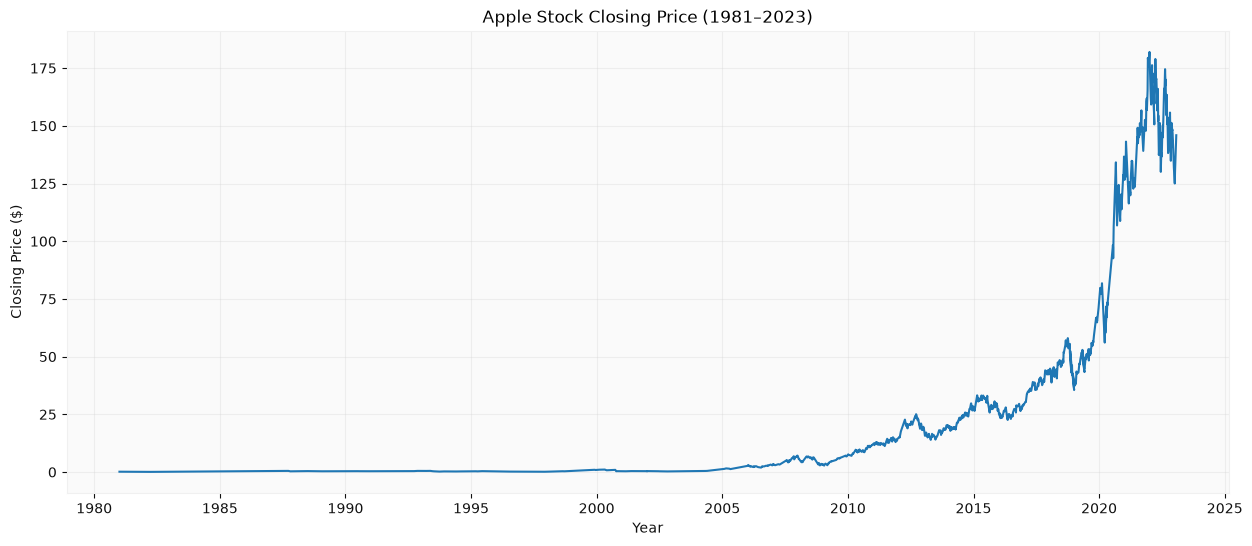

In [97]:
# Plot Apple's closing stock price over time

# Create a figure with a width of 15 inches and height of 6 inches
plt.figure(figsize=(15, 6))

# Plot the closing price against the date index
plt.plot(df.index, df['Close'])

# Add a title to the chart
plt.title('Apple Stock Closing Price (1981–2023)')

# Label the x-axis and y-axis
plt.xlabel('Year')
plt.ylabel('Closing Price ($)')

# Add a light grid to make the chart easier to read
plt.grid(True, alpha=0.3)

# Display the chart
plt.show()

1. Apple's Stock Price Shows Strong Long-Term Growth

The closing price chart demonstrates a clear and sustained upward trend over the 42-year period.

Key observations:
Between 1981 and the early 2000s, Apple's stock price remained relatively low and stable.
Growth began to accelerate after 2005.
The strongest period of growth occurred between 2019 and 2022, when the stock price increased dramatically.
The stock reached its highest levels in 2022, exceeding $175 per share.
A moderate decline occurred during 2023, although the price remained significantly higher than historical levels.

Conclusion: Apple stock has experienced exceptional long-term appreciation, reflecting the company's transformation into one of the world's largest and most valuable technology firms.

2. Trading Volume Exhibits High Volatility

Unlike stock prices, trading volume does not show a smooth long-term trend.
Key observations:
Trading volume fluctuates considerably throughout the dataset.
Several extreme spikes are visible, particularly around:
1997–2001
2005–2009
The largest spike occurs around 2000–2001, suggesting unusually high trading activity.
After approximately 2010, overall volume gradually declines despite continued growth in stock price.

Conclusion: Trading activity varies substantially over time and is influenced by specific market events rather than following the long-term price trend.

3. Price Growth and Trading Volume Do Not Closely Track Each Other

Comparing the price and volume charts reveals that:
Apple's stock price continued to rise sharply after 2010.
Trading volume did not increase at the same rate.
Some of the highest trading volumes occurred years before Apple's highest stock prices.

Conclusion: There appears to be only a weak relationship between long-term stock price growth and trading volume.

4. Increased Volatility in Recent Years

The closing-price chart shows larger swings after 2020 compared with earlier decades.

Examples include:
Rapid increases during 2020–2022.
Noticeable pullbacks and corrections during 2022–2023.

Conclusion: While Apple maintained a strong upward trend, market volatility increased during recent years.

Overall Conclusion
Analysis of Apple's stock data from 1981 to 2023 reveals a strong long-term upward trend in closing prices, with particularly rapid growth after 2010 and a peak in 2022. Trading volume fluctuates considerably and exhibits several major spikes, but it does not closely mirror the long-term increase in stock price. These findings suggest that Apple's share value has grown substantially over time while trading activity has been driven by individual market events rather than continuous price appreciation. The dataset therefore demonstrates both sustained long-term growth and periods of heightened market volatility.

C:\Users\USER1\AppData\Local\Temp\ipykernel_8568\1762789844.py:12: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('Date', inplace=True)


                Open      High       Low     Close
Date                                              
1981-01-02  0.154018  0.155134  0.154018  0.154018
1981-01-05  0.151228  0.151228  0.150670  0.150670
1981-01-06  0.144531  0.144531  0.143973  0.143973
1981-01-07  0.138393  0.138393  0.137835  0.137835
1981-01-08  0.135603  0.135603  0.135045  0.135045


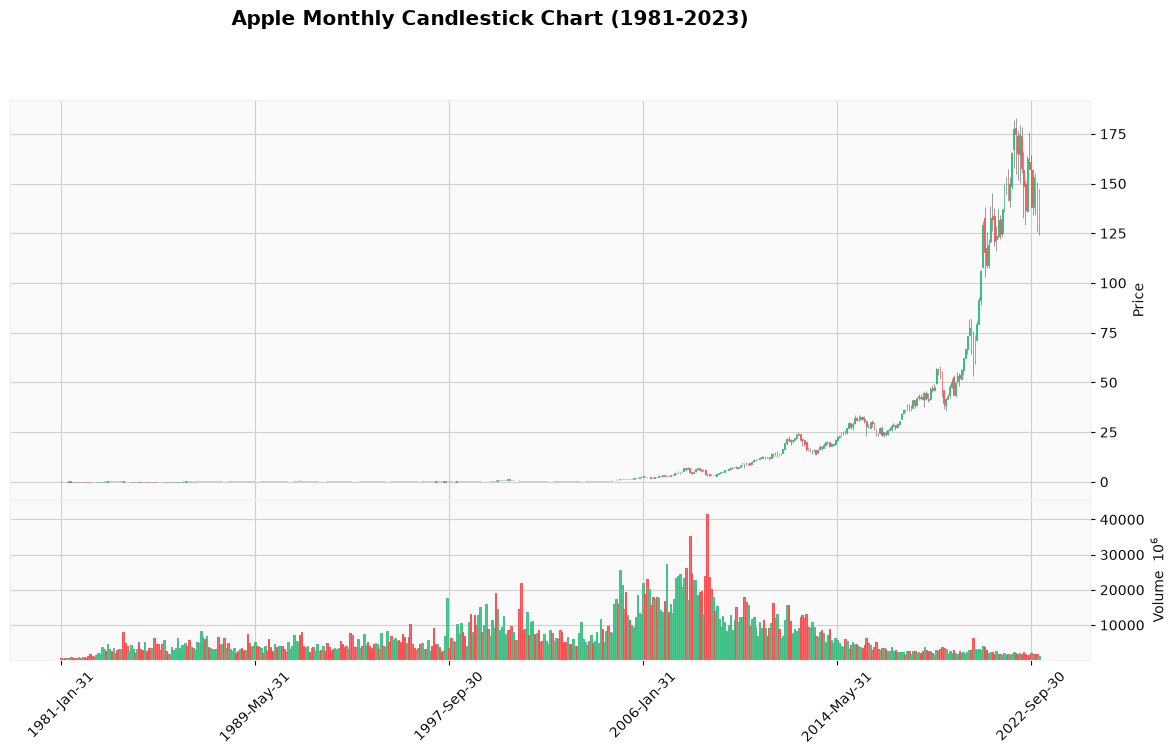

c:\Users\USER1\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\mplfinance\_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


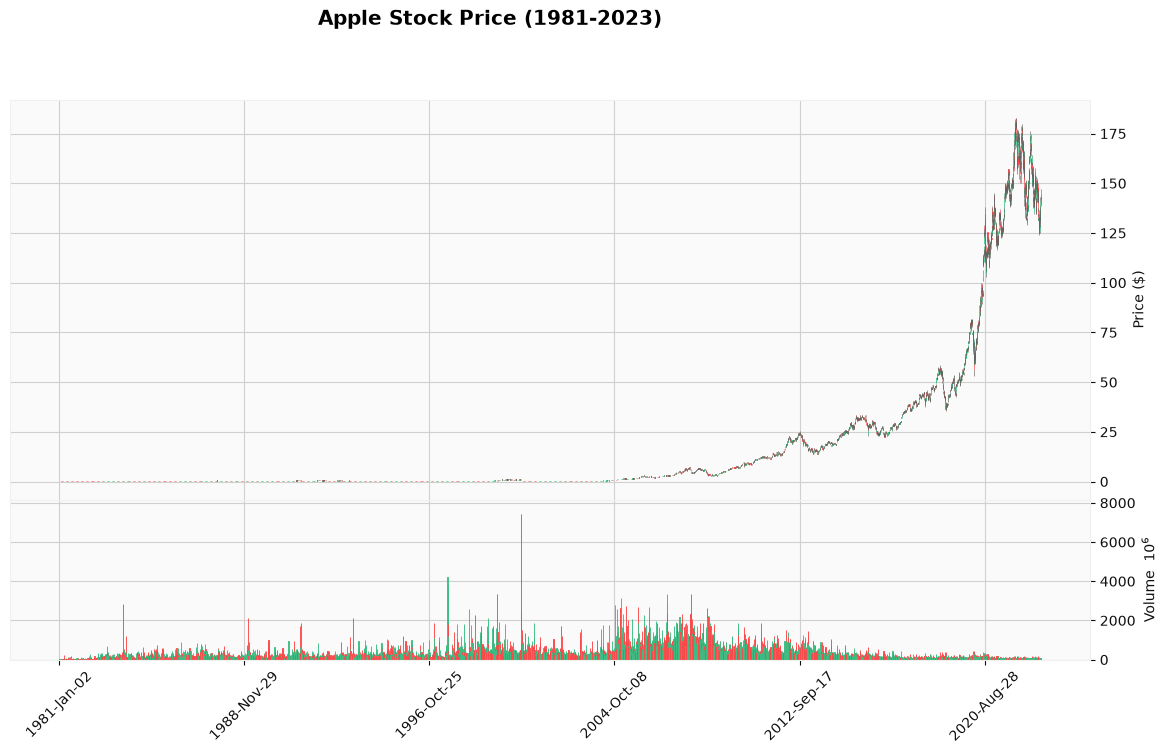

In [98]:
# Create a candlestick chart to visualise Apple's stock price movements over time

# Load the Apple stock dataset into a DataFrame
df = pd.read_csv("Apple-Stock-Prices-1981-2023.csv")

# Convert the Date column from text format to datetime format
# dayfirst=True interprets dates as DD/MM/YYYY
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Set the Date column as the DataFrame index
# This is required for resampling and financial charting
df.set_index('Date', inplace=True)

# Display the first five rows of the key price columns
# to verify the data loaded correctly
print(df[['Open', 'High', 'Low', 'Close']].head())

# Create monthly candlestick data

# Resample daily stock data into monthly intervals. This reduces over 40 years of daily records into a more readable chart
monthly = df.resample('ME').agg({

    # Opening price from the first trading day of the month
    'Open': 'first',

    # Highest stock price reached during the month
    'High': 'max',

    # Lowest stock price reached during the month
    'Low': 'min',

    # Closing price from the final trading day of the month
    'Close': 'last',

    # Total volume traded during the month
    'Volume': 'sum'
})

# Plot the monthly candlestick chart

mpf.plot(

    # Use the monthly resampled data
    monthly,

    # Display candlesticks
    type='candle',

    # Apply Yahoo Finance chart styling
    style='yahoo',

    # Show trading volume beneath the candlestick chart
    volume=True,

    # Chart title
    title='Apple Monthly Candlestick Chart (1981-2023)',

    # Figure size in inches
    figsize=(15,8)
)

# Plot the original daily candlestick chart

# NOTE:
# Daily data from 1981-2023 contains more than 10,000
# trading days, so the chart may appear crowded.

mpf.plot(

    # Use the original daily stock data
    df,

    # Create candlesticks
    type='candle',

    # Apply Yahoo Finance styling
    style='yahoo',

    # Add chart title
    title='Apple Stock Price (1981-2023)',

    # Label the price axis
    ylabel='Price ($)',

    # Include trading volume panel
    volume=True,

    # Set chart size
    figsize=(15, 8)
)

Detailed Findings from the Monthly Candlestick Chart (1981–2023)
1. Strong Long-Term Upward Trend

The chart clearly shows that Apple experienced substantial long-term growth over the 42-year period.

From 1981 to approximately 2004, the stock traded at relatively low price levels with modest growth.
After 2005, the stock entered a sustained upward trend.
Growth accelerated significantly after 2010, with increasingly larger monthly gains.
The most dramatic appreciation occurred between 2020 and 2022, when the stock price rose from approximately $60 to over $175.

Finding: Apple transformed from a relatively low-priced stock into one of the highest-valued companies in the market.

2. Different Growth Phases Are Visible

The candlestick chart reveals several distinct periods:

Early Growth Phase (1981–2004)
- Small candlesticks indicate limited monthly price movement.
- Stock prices remained relatively stable.
- Volatility was low compared to later years.
Expansion Phase (2005–2013)
- Candlesticks begin increasing in size.
- The stock shows a stronger upward trajectory.
- More frequent bullish (upward) months appear.
Rapid Growth Phase (2014–2019)
- Price appreciation accelerates.
- Higher highs and higher lows become evident.
- Monthly price ranges become larger.
High-Growth / High-Volatility Phase (2020–2023)
- Largest candlesticks in the entire dataset.
- Significant monthly gains and losses occur.
- Price reaches record highs before experiencing pullbacks.
3. Increased Volatility in Recent Years

Volatility can be seen through:
- Larger candlestick bodies.
- Longer upper and lower wicks.
- Greater distance between monthly highs and lows.

Between 2020 and 2023, candlesticks become substantially larger than in previous decades.
This indicates:
- Larger monthly price swings.
- Increased investor activity.
- Greater uncertainty and market sensitivity.
Finding: Apple's stock became significantly more volatile while continuing its upward trend.

4. Evidence of Market Corrections

Several periods show temporary declines after strong growth:
- Around 2008–2009, prices fell before recovering.
- Around 2012–2013, a correction occurred after rapid gains.
- Around 2018–2019, another pullback is visible.
- A notable decline appears after the 2022 peak.

These corrections are common in long-term bull markets.

Finding: Despite periodic downturns, the overall direction of the stock remains strongly upward.

5. Trading Volume Peaks Before Price Peaks

The volume panel shows:
- Extremely large volume spikes between approximately 1997 and 2009.
- The highest recorded volume appears around 2000–2001.
- Trading volume remains elevated during 2005–2008.
- Volume trends downward after approximately 2010, despite continued price growth.

This suggests:
- Higher trading activity during periods of uncertainty or major market events.
- Increased stock price does not necessarily correspond to increased volume.
Finding: Trading volume and stock price do not move together consistently over time.

6. Bullish Period Dominates the Chart

A large proportion of candlesticks are bullish (green/upward months), particularly:
2004–2007
2009–2012
2016–2019
2020–2021

These periods contributed significantly to Apple's long-term appreciation.

Finding: The stock spent more time rising than falling over the entire study period.

Overall Conclusion
The monthly candlestick chart reveals a strong long-term bullish trend in Apple's stock price from 1981 to 2023. Price growth was relatively modest during the first two decades but accelerated substantially after 2005 and especially after 2010. The stock reached record highs in 2022 before experiencing a moderate correction. Volatility increased considerably in recent years, as shown by larger candlesticks and wider monthly trading ranges. Trading volume peaked between the late 1990s and late 2000s but generally declined thereafter, indicating that rising stock prices were not necessarily accompanied by increasing trading activity. Overall, the chart illustrates Apple's transformation into one of the world's most valuable and actively traded companies.

In [99]:
# Compute summary statistics for key stock market variables

# Create a list containing the financial columns that will be included in the statistical analysis
columns = [
    'Open',
    'High',
    'Low',
    'Close',
    'Adj Close',
    'Volume'
]

# Calculate statistics using Pandas
# Create a DataFrame containing summary statistics for each selected column

summary_stats = pd.DataFrame({

    # Calculate the arithmetic mean (average)
    'Mean': df[columns].mean(),

    # Calculate the median (middle value)
    'Median': df[columns].median(),

    # Calculate the standard deviation
    # This measures the variability of the data
    'Standard Deviation': df[columns].std()
})

# Display summary statistics
print(summary_stats)

# Calculate the same statistics using NumPy
# Loop through each selected column
for col in columns:

    # Print the name of the current column
    print(f"\n{col}")

    # Calculate and display the mean
    print("Mean:", np.mean(df[col]))

    # Calculate and display the median
    print("Median:", np.median(df[col]))

    # Calculate and display the standard deviation
    print("Standard Deviation:", np.std(df[col]))

# Create a cleaner summary table for reporting

# Round values to two decimal places for readability
summary_stats = pd.DataFrame({

    # Average value for each variable
    'Mean': df[columns].mean().round(2),

    # Middle value for each variable
    'Median': df[columns].median().round(2),

    # Measure of variation around the mean
    'Std Dev': df[columns].std().round(2)
})

# Display the final formatted summary table
print(summary_stats)

                   Mean        Median  Standard Deviation
Open       1.668917e+01  4.888390e-01        3.545052e+01
High       1.687996e+01  4.955360e-01        3.588285e+01
Low        1.650082e+01  4.804465e-01        3.503129e+01
Close      1.669736e+01  4.877010e-01        3.547391e+01
Adj Close  1.602735e+01  4.048505e-01        3.515488e+01
Volume     3.275098e+08  2.145976e+08        3.378203e+08

Open
Mean: 16.689172588518105
Median: 0.488839
Standard Deviation: 35.44884791090304

High
Mean: 16.879955221342385
Median: 0.495536
Standard Deviation: 35.8811564385601

Low
Mean: 16.500821578525642
Median: 0.4804465
Standard Deviation: 35.029637288417504

Close
Mean: 16.69736201451735
Median: 0.487701
Standard Deviation: 35.47223956417653

Adj Close
Mean: 16.02734531806184
Median: 0.4048505
Standard Deviation: 35.153220860069126

Volume
Mean: 327509817.26055807
Median: 214597600.0
Standard Deviation: 337804355.78091294
                   Mean        Median       Std Dev
Open       1.6

1. Stock Price Variables (Open, High, Low, Close)
Large Difference Between Mean and Median

One of the most important findings is that the mean is much larger than the median.

For example:
Mean Closing Price = 16.70
Median Closing Price = 0.49

This is a very large difference.

What does this mean?
The distribution of Apple's stock prices is highly right-skewed.
For much of the 1980s, 1990s, and early 2000s, Apple traded at relatively low prices. However, in recent years the stock price increased dramatically, particularly after 2010.
Because the mean is sensitive to extreme values, these recent high prices pull the average upward.

The median tells us that:
Half of all recorded trading days had a closing price below approximately $0.49.
This reflects the fact that Apple's share price spent a large portion of its history at very low levels before experiencing rapid growth.

2. High Standard Deviations Indicate Significant Volatility

For the price variables:

Variable	Std Dev
Open	35.45
High	35.88
Low	35.03
Close	35.47
Adj Close	35.15

The standard deviations are more than double the mean values.

This indicates:
- Large fluctuations in stock price.
- Significant changes over time.
- Wide variation between early and recent stock prices.
- Interpretation
- Apple's stock has not remained stable over the 42-year period.

Instead, the company has experienced:
- Extended growth phases.
- Periods of decline and correction.
- Major increases in valuation, especially during the last decade.

The high standard deviation confirms the strong upward trend observed in the price charts.

3. High, Low, Open, and Close Are Very Similar

Notice how closely the averages align:

Variable	Mean
Open	16.69
High	16.88
Low	16.50
Close	16.70

The differences are relatively small.

Interpretation

This suggests that:

Daily price movements tend to be relatively contained.
The stock usually opens and closes within a predictable range.
Extreme intraday swings are uncommon relative to the overall long-term trend.

The High price being slightly greater than the others is expected because it represents the highest value reached during the trading day.

Similarly, the Low price naturally has the lowest average.

4. Adjusted Close Is Slightly Lower Than Close
Mean Close = 16.70
Mean Adjusted Close = 16.03

Adjusted Close accounts for:

Stock splits
Dividends
Corporate actions
Interpretation

The adjusted values provide a more accurate measure of long-term shareholder returns and explain why Adjusted Close is slightly lower on average.

5. Trading Volume Shows Huge Variability

Statistics for Volume:
Mean = 327.5 million
Median = 214.6 million
Standard Deviation = 337.8 million

Again, we see:
Mean > Median
which indicates a right-skewed distribution.

What Does This Tell Us?
Most trading days had volumes below the average.
However, a smaller number of days experienced exceptionally high trading activity.

These spikes were likely caused by:
- Earnings announcements
- Major product launches
- Stock splits
- Financial crises
- Significant market events

The volume chart supports this observation, showing numerous large volume surges.

6. Evidence of Apple's Long-Term Growth

The combination of:
- Very low median prices
- Much higher means
- Large standard deviations
suggests that Apple underwent substantial growth throughout the observation period.

For example:
Median Close = $0.49
Mean Close = $16.70

The stock spent many years trading at fractions of a dollar (split-adjusted), yet eventually reached levels above $150.

This causes the average to rise dramatically.

Overall Conclusion
The summary statistics reveal that Apple's stock experienced extraordinary long-term growth between 1981 and 2023. The large gap between the mean and median prices indicates a highly right-skewed distribution, reflecting decades of relatively low prices followed by substantial appreciation in recent years. High standard deviations across all price variables suggest significant variability and long-term trend changes rather than stable price behaviour. Trading volume also displays considerable variability, with several periods of unusually high investor activity. Together, these statistics support the visual findings from the time-series analysis and demonstrate Apple's transformation from a relatively small technology company into one of the world's most valuable publicly traded firms.

               Close  MA30
Date                      
1981-01-02  0.154018   NaN
1981-01-05  0.150670   NaN
1981-01-06  0.143973   NaN
1981-01-07  0.137835   NaN
1981-01-08  0.135045   NaN


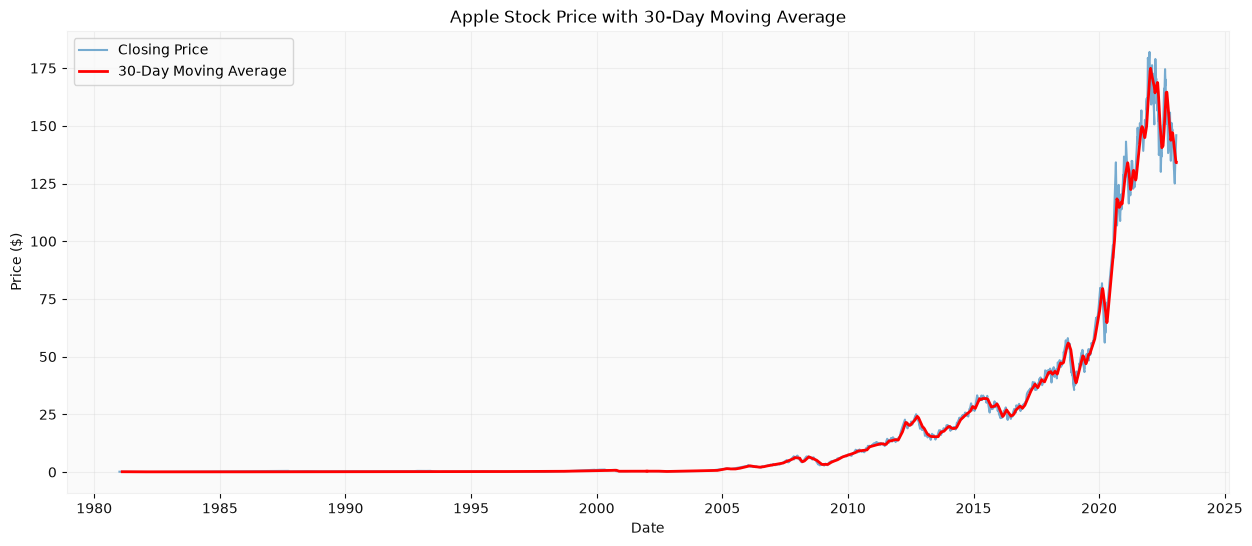

<module 'matplotlib.pyplot' from 'c:\\Users\\USER1\\AppData\\Local\\Python\\pythoncore-3.15-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

<Figure size 1500x600 with 0 Axes>

In [100]:
# Analyse Apple's closing prices using moving averages

# Calculate the 30-day moving average of the closing price
# A moving average smooths short-term fluctuations and helps reveal the underlying trend in the stock price
df['MA30'] = df['Close'].rolling(window=30).mean()

# Display the first few rows of the Close price and the newly calculated 30-day moving average
# The first 29 rows will contain NaN values because 30 days of data are required before a moving average can be calculated
print(df[['Close', 'MA30']].head())

# Plot the closing price and 30-day moving average

# Create a figure with a width of 15 inches and height of 6 inches
plt.figure(figsize=(15, 6))

# Plot Apple's actual daily closing prices
# alpha=0.6 makes the line slightly transparent
plt.plot(
    df.index,
    df['Close'],
    label='Closing Price',
    alpha=0.6
)

# Plot the 30-day moving average
# The red line highlights the underlying trend by reducing daily market noise
plt.plot(
    df.index,
    df['MA30'],
    label='30-Day Moving Average',
    color='red',
    linewidth=2
)

# Add chart title
plt.title('Apple Stock Price with 30-Day Moving Average')

# Label the x-axis
plt.xlabel('Date')

# Label the y-axis
plt.ylabel('Price ($)')

# Display the legend explaining each line
plt.legend()

# Add grid lines to improve readability
plt.grid(True, alpha=0.3)

# Display the chart
plt.show()

# Analyse long-term trends using multiple moving averages

# Calculate the 50-day moving average used to identify medium-term market trends
df['MA50'] = df['Close'].rolling(window=50).mean()

# Calculate the 200-day moving average widely used to identify long-term market direction
df['MA200'] = df['Close'].rolling(window=200).mean()


# Create a new figure for comparing moving averages
plt.figure(figsize=(15, 6))

# Plot the original closing price
# Transparency is increased to make moving averages easier to see
plt

For the table:
This is expected because a 30-day moving average requires 30 previous trading days before it can calculate an average.

Therefore:
Days 1-29 have no moving average value.
The first valid MA30 value appears on approximately the 30th trading day.
This is normal behaviour and not a data quality issue.
The chart clearly demonstrates that Apple's stock has experienced substantial long-term growth.

Early Period (1981-2004)
- The stock price remained very low for over two decades.
- The 30-day moving average is almost flat.
- Daily price fluctuations were relatively small.
This suggests Apple experienced modest growth during this period.

Growth Period (2005-2012)

Around 2005:
- The closing price begins rising steadily.
- The moving average also begins trending upward.
- The moving average closely follows the underlying direction of the stock.

This indicates sustained positive price momentum.

Expansion Period (2013-2019)

Between 2013 and 2019:
- The stock continues making higher highs.
- The moving average becomes steeper.
- Several temporary pullbacks occur, but the overall upward trend remains intact.

The moving average helps filter out short-term volatility and clearly shows continued growth.

High-Growth Period (2020-2022)

This is the most dramatic section of the chart.
Observations:
- The stock price rises extremely rapidly.
- Closing prices reach approximately $180.
- The moving average rises sharply as well.
- Large gaps occasionally appear between the closing price and the moving average.

This suggests:
- Strong bullish momentum.
- Significant investor confidence.
- Rapid appreciation in Apple's market value.

3. The Moving Average Smooths Volatility

Notice that:
- The blue line (daily closing price) contains many short-term fluctuations.
- The red line (30-day moving average) is much smoother.

The moving average removes "noise" from daily trading activity and makes the underlying trend easier to identify.

This helps investors distinguish:
- Temporary price swings
- Long-term market direction

4. Evidence of Market Corrections

Several periods show the stock price falling below the moving average.

Examples appear around:
2008–2009
2015–2016
2018–2019
2022–2023

When this occurs:
- Prices weaken in the short term.
- Momentum slows.
- The market may be entering a correction phase.

However, most of these declines are temporary.

5. The Moving Average Confirms Apple's Bullish Trend

For most of the chart:
- The stock price remains above or very close to the 30-day moving average.
- The moving average consistently slopes upward.

This indicates:
- A persistent long-term bullish trend.
- Continued shareholder value creation.
- Strong market performance over several decades.
Overall Conclusion
The 30-day moving average analysis confirms that Apple experienced a strong long-term upward trend between 1981 and 2023. During the early decades the stock price remained relatively stable, but growth accelerated significantly after 2005 and especially after 2020. The moving average successfully smooths short-term market fluctuations, revealing sustained long-term appreciation in Apple's stock value. Although periodic corrections occurred, the overall direction remained consistently upward, demonstrating Apple's remarkable expansion and market success over the study period.

In [ ]:
# Comparing two years, using 2022 vs 2023

# Create a year column as Date is your index
df['Year'] = df.index.year

# Select closing prices for two years
close_2022 = df[df['Year'] == 2022]['Close']
close_2023 = df[df['Year'] == 2023]['Close']

# Independent t-test
t_stat, p_value = ttest_ind(
    close_2022,
    close_2023,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The average closing prices differ significantly.")
else:
    print("Fail to reject the null hypothesis")
    print("No significant difference in average closing prices.")

# Compare more years

years_to_compare = [1985, 1995, 2005, 2015, 2023]

for i in range(len(years_to_compare)):
    for j in range(i + 1, len(years_to_compare)):

        year1 = years_to_compare[i]
        year2 = years_to_compare[j]

        close1 = df[df['Year'] == year1]['Close']
        close2 = df[df['Year'] == year2]['Close']

        t_stat, p_value = ttest_ind(
            close1,
            close2,
            equal_var=False
        )

        print(f"{year1} vs {year2}: p-value = {p_value:.5f}")

results = []

# Create a Year column from the Date index
df['Year'] = df.index.year

# Get all unique years and sort them
years = sorted(df['Year'].unique())

print(years[:10])  # Verify

for i in range(len(years) - 1):

    year1 = years[i]
    year2 = years[i + 1]

    close1 = df[df['Year'] == year1]['Close']
    close2 = df[df['Year'] == year2]['Close']

    t_stat, p_value = ttest_ind(
        close1,
        close2,
        equal_var=False
    )

    results.append([
        year1,
        year2,
        t_stat,
        p_value
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Year 1',
        'Year 2',
        'T Statistic',
        'P Value'
    ]
)

print(results_df)

T-statistic: 11.581631084617255
P-value: 2.761845125088065e-12
Reject the null hypothesis
The average closing prices differ significantly.
1985 vs 1995: p-value = 0.00000
1985 vs 2005: p-value = 0.00000
1985 vs 2015: p-value = 0.00000
1985 vs 2023: p-value = 0.00000
1995 vs 2005: p-value = 0.00000
1995 vs 2015: p-value = 0.00000
1995 vs 2023: p-value = 0.00000
2005 vs 2015: p-value = 0.00000
2005 vs 2023: p-value = 0.00000
2015 vs 2023: p-value = 0.00000
[np.int32(1981), np.int32(1982), np.int32(1983), np.int32(1984), np.int32(1985), np.int32(1986), np.int32(1987), np.int32(1988), np.int32(1989), np.int32(1990)]
    Year 1  Year 2  T Statistic        P Value
0     1981    1982    10.579143   1.153055e-23
1     1982    1983   -21.354763   2.082319e-66
2     1983    1984    13.652210   1.438182e-32
3     1984    1985    20.852690   6.432532e-64
4     1985    1986   -27.226580   1.027048e-99
5     1986    1987   -40.464088  1.219252e-124
6     1987    1988    -4.656697   4.863445e-06
7   

Why This Analysis Is Useful
2022 vs 2023 determines whether Apple's average closing price changed significantly between those years.
1985, 1995, 2005, 2015, and 2023 comparisons demonstrate how Apple's stock evolved across major stages of the company's development.
Consecutive-year comparisons identify periods where statistically significant shifts occurred, helping pinpoint years of major growth, decline, or market disruption.

The hypotheses were:
Null Hypothesis (H₀): The average closing price in 2022 is equal to the average closing price in 2023.
Alternative Hypothesis (H₁): The average closing price in 2022 is different from the average closing price in 2023.

Every comparison between:
1985
1995
2005
2015
2023
produced a p-value effectively equal to zero.

This means:
- The average stock price in each period was significantly different from the others.
This is exactly what we would expect from a company that experienced substantial long-term growth.

Negative values indicate the stock price increased.
Positive values indicate the stock price decreased compared with the following year.

Most years have P-value < 0.05 indicating statistically significant changes in average closing prices.

This suggests Apple experienced frequent year-to-year price changes rather than remaining at a stable valuation.

Major growth periods are observable around:

1997–2000
2004–2007
2009–2012
2016–2021

These periods coincide with the strong upward trends visible in the stock charts.

5. Years With No Significant Difference

A few comparisons produced relatively large p-values:
1988 vs 1989 = 0.6956
2002 vs 2003 = 0.0829
2008 vs 2009 = 0.1416

Interpretation
For these years P-value > 0.05

Therefore:
We fail to reject the null hypothesis.

The average closing prices were statistically similar during those periods.

This suggests temporary periods where Apple's stock price remained relatively stable before resuming stronger growth.

Overall Conclusion
The t-test analysis provides strong evidence that Apple's average closing price changed significantly over time. Comparisons between major historical periods (1985, 1995, 2005, 2015, and 2023) all show highly significant differences, reflecting the company's substantial long-term growth. Consecutive-year testing also indicates that most annual changes were statistically significant, highlighting the dynamic nature of Apple's stock performance. The only exceptions occurred during a few relatively stable periods, where average prices did not differ significantly between adjacent years. Overall, the statistical results strongly support the visual findings from the price charts, demonstrating that Apple's stock value increased dramatically between 1981 and 2023.


Mean Return: 0.0010518641495988169
Median Return: 0.0
Standard Deviation: 0.028235401440258164
Skewness: -0.37529222936664286
Kurtosis: 18.134276736620222


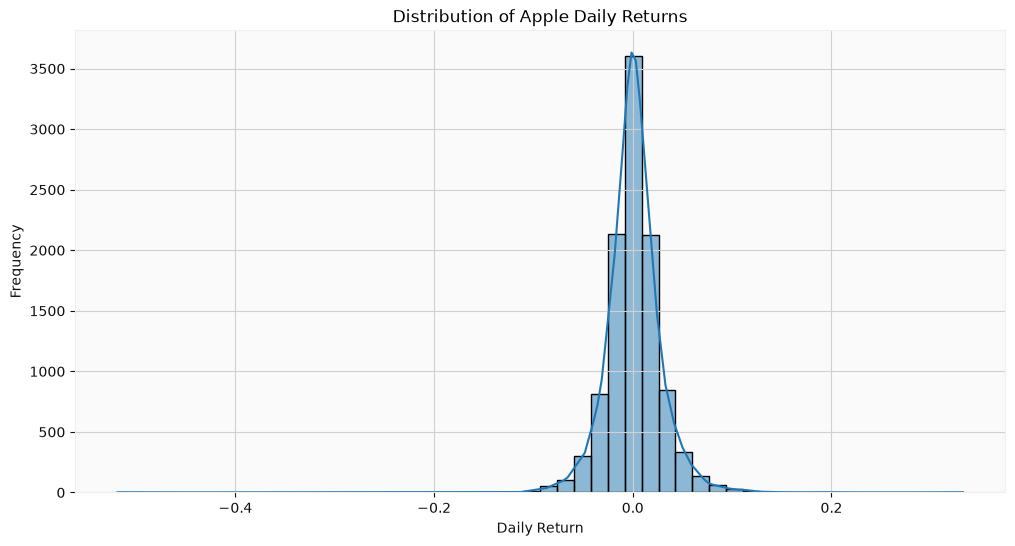

Statistic: 0.9531905638887235
P-value: 2.7030229157869115e-37
Reject H0: Returns are not normally distributed
Statistic: 2719.2052873659354
P-value: 0.0
Returns are not normally distributed


In [101]:
# Examine the distribution of Apple's daily returns and test whether returns follow a normal distribution

# Calculate daily percentage returns pct_change() measures the percentage change in closing price from one trading day to the next
df['Daily_Return'] = df['Close'].pct_change()

# Remove the first NaN value
# The first observation has no previous day for comparison, so pct_change() produces a missing value
returns = df['Daily_Return'].dropna()

# Calculate descriptive statistics for daily returns

# Average daily return
# Indicates whether the stock tends to gain or lose value over time
print("Mean Return:", returns.mean())

# Median daily return
# Represents the middle daily return value
print("Median Return:", returns.median())

# Standard deviation of returns
# Measures daily price volatility
print("Standard Deviation:", returns.std())

# Skewness
# Indicates whether the distribution is symmetric
# Positive = longer right tail
# Negative = longer left tail
print("Skewness:", returns.skew())

# Kurtosis
# Measures the heaviness of the tails relative to a normal distribution
# High kurtosis suggests more extreme returns
print("Kurtosis:", returns.kurt())

# Visualise the distribution of daily returns

# Create a histogram figure
plt.figure(figsize=(12,6))

# Plot the distribution of daily returns
sns.histplot(

    # Daily return values
    returns,

    # Number of histogram bins
    bins=50,

    # Overlay a density curve to show the distribution shape
    kde=True
)

# Add chart title
plt.title('Distribution of Apple Daily Returns')

# Label x-axis
plt.xlabel('Daily Return')

# Label y-axis
plt.ylabel('Frequency')

# Display chart
plt.show()

# Perform the Shapiro-Wilk normality test
# The Shapiro test performs best on smaller datasets
# Therefore a random sample of 5,000 observations is used
sample = returns.sample(
    5000,
    random_state=42
)

# Run the Shapiro-Wilk test
# H0: Data follows a normal distribution
# H1: Data does not follow a normal distribution
statistic, p_value = shapiro(sample)

# Display test statistic
print("Statistic:", statistic)

# Display p-value
print("P-value:", p_value)

# Interpret the result
if p_value < 0.05:

    # Reject null hypothesis
    print("Reject H0: Returns are not normally distributed")

else:

    # Fail to reject null hypothesis
    print("Fail to reject H0: Returns appear normal")

# Perform the D'Agostino-Pearson normality test

# This test is well suited for larger datasets. It evaluates skewness and kurtosis simultaneously

# H0: Returns are normally distributed
# H1: Returns are not normally distributed
statistic, p_value = normaltest(returns)

# Display test statistic
print("Statistic:", statistic)

# Display p-value
print("P-value:", p_value)

# Interpret the result
if p_value < 0.05:

    # Reject null hypothesis
    print("Returns are not normally distributed")

else:

    # Fail to reject null hypothesis
    print("Returns appear normally distributed")

On average, Apple's stock gained approximately 0.105% per trading day over the period 1981–2023.

Although this may appear small, daily returns compound over time. A positive average daily return accumulated over thousands of trading days contributes significantly to Apple's substantial long-term growth.

What this suggests
- Apple generated a positive long-term return.
- The stock exhibited overall appreciation during the study period.

2. Median Daily Return
Median Return = 0.0

Interpretation
The median return being very close to zero means that:
Half of all trading days produced returns below 0%.
Half of all trading days produced returns above 0%.
Most daily changes were relatively small.

What this suggests
While Apple experienced tremendous long-term growth, that growth did not occur through large gains every day.

Instead:
Most days experienced only minor price changes.
Long-term growth resulted from the cumulative effect of many small gains over time.

3. Standard Deviation
Standard Deviation = 0.0282

Equivalent to:
2.82%

Interpretation
Daily returns typically fluctuate by approximately ±2.8% around the average daily return.
This is a measure of volatility.

What this suggests
Apple stock can experience noticeable day-to-day price fluctuations.

Examples:
+3%, -2%, +4% -1% are not unusual.

The standard deviation indicates moderate-to-high volatility, which is common in technology stocks.

4. Skewness
Skewness = -0.375

Interpretation
The negative value indicates that the distribution is slightly left-skewed.

This means:
- Negative returns extend further than positive returns.
- Large price drops occur slightly more often than equally large price increases.

Graphically:
Peak
/\
/ \
____/ \______
\
\
Longer left tail

What this suggests
Although Apple generally increased in value over time, occasional sharp declines occurred.

Such declines may correspond to:
- Market crashes
- Recessions
- Financial crises
- Technology-sector sell-offs

5. Kurtosis
Kurtosis = 18.13

Interpretation
This is extremely high.

For reference:
Normal distribution kurtosis ≈ 0

Result:
18.13 - indicates a leptokurtic distribution.

What this means
The distribution has:
- A very sharp central peak.
- Much heavier tails than a normal distribution.
- Many more extreme observations than expected under normality.

In simple terms:
- Large gains and losses happened more frequently than a normal distribution would predict.
- This is extremely common in financial markets.

6. Histogram Interpretation
The histogram provides visual confirmation of the statistical measures.

Observations
- Strong central peak
- Most observations cluster around 0%.

This supports:
Median ≈ 0

Most daily returns are small.

Heavy tails
The histogram stretches far into both positive and negative territory.

Returns extend approximately:
From around -50% to around +30%

Although these extreme returns are rare, they occur more frequently than would be expected under a normal distribution.

This is reflected in the very high kurtosis.

Slight left skew -The negative side extends slightly farther than the positive side.

This agrees with: Skewness = -0.375 and suggests downside shocks are somewhat larger than upside shocks.

What This Means for Investors
The results indicate that:
- Positive Long-Term Performance
- Daily returns are positive on average.
- Apple generated substantial wealth over the long run.
- Significant Volatility
- Daily returns fluctuate meaningfully.
- Investors must tolerate short-term uncertainty.
- Risk of Extreme Events

The high kurtosis suggests:
- Extreme gains and losses occur more frequently than expected under a normal distribution.
- Traditional models assuming normality may underestimate risk.
- Evidence Against Normality

The combination of:
Skewness = -0.375
Kurtosis = 18.13
strongly suggests that Apple's daily returns are not normally distributed.
This is exactly what is commonly observed in real-world financial markets.

Conclusion
Analysis of Apple's daily returns reveals a positive average return of approximately 0.105% per trading day, indicating long-term stock appreciation between 1981 and 2023. The median return of zero suggests that most daily price movements were relatively small and centred around no change. A standard deviation of 2.82% indicates moderate daily volatility. The return distribution exhibits slight negative skewness (-0.375), implying that large negative returns occur somewhat more frequently than large positive returns. Most notably, the extremely high kurtosis value (18.13) indicates heavy tails and a higher frequency of extreme market movements than would be expected under a normal distribution. The histogram confirms these findings, showing a sharp concentration of returns around zero with occasional substantial positive and negative price changes.

Mean: 16.69736201451735
Median: 0.487701
Standard Deviation: 35.47223956417653
Minimum: 0.049107
Maximum: 182.009995
Mean Daily Return: 0.0010518641495988175
Volatility: 0.028234070429276666
[0.1357143  0.134375   0.1332403  0.13249627 0.131715   0.13082213
 0.12974327 0.1285714  0.12779013 0.12704607]


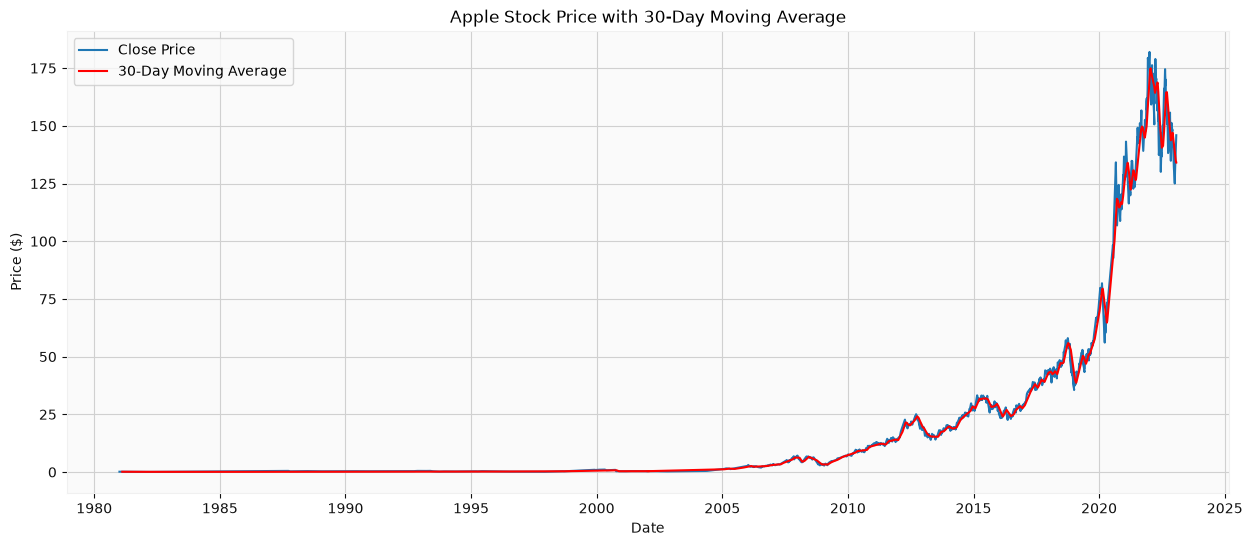

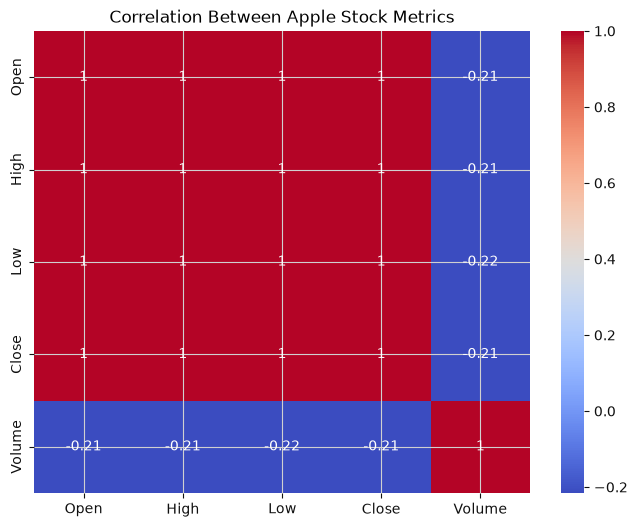

In [102]:
# Use NumPy statistical functions to analyse Apple stock data
# Extract the Close price column as a NumPy array
# NumPy arrays allow efficient mathematical operations
close = df['Close'].values

# Calculate descriptive statistics for closing prices
# Calculate the average closing price across the dataset
print("Mean:", np.mean(close))

# Calculate the median (middle) closing price
print("Median:", np.median(close))

# Calculate the standard deviation
# Measures how much closing prices vary from the average
print("Standard Deviation:", np.std(close))

# Find the lowest closing price recorded
print("Minimum:", np.min(close))

# Find the highest closing price recorded
print("Maximum:", np.max(close))

# Calculate daily stock returns using NumPy

# Calculate percentage daily returns
# Formula:
# (Today's Price - Yesterday's Price) / Yesterday's Price
returns = np.diff(close) / close[:-1]

# Calculate average daily return
print("Mean Daily Return:", np.mean(returns))

# Calculate return volatility
# Standard deviation of returns is commonly used as a measure of investment risk
print("Volatility:", np.std(returns))


# Calculate a 30-day moving average using np.convolve()
# Define the moving-average window size
window = 30

# Create a moving average using convolution
# np.ones(window)/window creates equal weights mode='valid' only returns fully populated averages
moving_avg = np.convolve(
    close,
    np.ones(window) / window,
    mode='valid'
)

# Display the first 10 moving-average values
print(moving_avg[:10])

# Visualise the closing price and moving average
# Import plotting library
import matplotlib.pyplot as plt

# Create chart figure
plt.figure(figsize=(15, 6))

# Plot Apple's daily closing price
plt.plot(
    df.index,
    close,
    label='Close Price'
)

# Plot the moving average on top of the closing price
# Start plotting at index[window-1] because the first moving average is produced after 30 observations
plt.plot(
    df.index[window-1:],
    moving_avg,
    color='red',
    label='30-Day Moving Average'
)

# Add chart title
plt.title('Apple Stock Price with 30-Day Moving Average')

# Label x-axis
plt.xlabel('Date')

# Label y-axis
plt.ylabel('Price ($)')

# Show line labels
plt.legend()

# Display chart
plt.show()

# Investigate correlations between stock variables

# Select key financial variables and calculate
# their pairwise correlation coefficients
corr_df = df[
    ['Open', 'High', 'Low', 'Close', 'Volume']
].corr()

# Visualise correlations using a heatmap

# Create figure
plt.figure(figsize=(8, 6))

# Draw correlation heatmap
sns.heatmap(

    # Correlation matrix
    corr_df,

    # Display correlation values inside each square
    annot=True,

    # Colour scale:
    # Red = positive correlation
    # Blue = negative correlation
    cmap='coolwarm'
)

# Add chart title
plt.title('Correlation Between Apple Stock Metrics')

# Display chart
plt.show()

Apple's stock price was extremely low at the beginning of the dataset.

This highlights how much the company grew over the following decades.

T-Test Analysis
2022 vs 2023

T-statistic = 11.58
P-value = 2.76 × 10⁻¹²

Since p < 0.05, we reject the null hypothesis.

Interpretation
The average closing price in 2022 differed significantly from the average closing price in 2023.

The positive t-statistic suggests:
Average closing prices were higher during 2022 than during 2023.

Historical Comparisons

Examples:
1985 vs 2023
p-value = 0.00000

1995 vs 2023
p-value = 0.00000

Interpretation

All major periods differ significantly.

This statistically confirms Apple's dramatic growth over four decades.

Daily Return Analysis
Mean Return - 0.00105

≈ 0.105% per trading day.

This indicates:
Apple provided positive average daily returns.

Median Return
0.0

Most trading days experienced relatively small price changes.

Volatility
Standard Deviation = 0.0282
≈ 2.82%

This indicates:

Moderate day-to-day volatility.

Skewness = -0.375

Slightly negative.

Meaning:
Large negative returns occur somewhat more frequently than equally large positive returns.

Kurtosis
18.13
This is extremely high.

For comparison:
Normal Distribution ≈ 0

Meaning:
Extreme stock movements occur much more frequently than a normal distribution predicts.

This is typical of financial markets.

Shapiro-Wilk Test
p-value = 2.70 × 10⁻³⁷

D'Agostino-Pearson Test
p-value = 0.0

Both tests conclude:
Returns are not normally distributed

Interpretation
Apple's daily returns are:
- Heavily concentrated around zero.
- Contain unusually large gains and losses.
- Violate the normality assumption.

This is very common in real-world stock market data.

Overall Conclusion
The Apple stock dataset is complete, contains no missing values, and spans over 42 years of trading history. The analysis reveals strong long-term growth in Apple's share price, particularly after 2010. Statistical tests confirm significant differences in stock prices across years, reflecting Apple's transformation into one of the world's most valuable companies. Daily returns exhibit positive average performance but are not normally distributed, showing moderate volatility, slight negative skewness, and very heavy tails. Together, the findings indicate sustained long-term appreciation combined with the episodic large price movements characteristic of financial markets.

1. Apple Stock Price with 30-Day Moving Average
What the chart shows
The blue line shows Apple's actual daily closing price.
The red line shows the 30-day moving average, which smooths out short-term fluctuations.
Key Findings
Strong long-term growth

The chart shows a dramatic increase in Apple's stock price over the period 1981–2023.

During the 1980s and most of the 1990s, prices remained very low.
Growth became more noticeable after 2005.
The steepest growth occurred between 2019 and 2022.
The stock peaked at approximately $180 before declining somewhat in 2023.

This confirms that Apple experienced substantial long-term appreciation.

The moving average follows the same trend

The red moving-average line closely tracks the stock price:

It rises steadily over time.
It smooths out daily volatility.
It makes the underlying trend easier to see.

This confirms that the growth was not caused by a few isolated price spikes but represented a sustained upward trend.

Periods of correction are visible

Several periods show the stock falling below its moving average:

Around 2008–2009
Around 2015–2016
Around 2018–2019
Around 2022–2023

These periods indicate temporary market corrections.

However, after each correction the long-term upward trend resumes.

Increased volatility in recent years

Notice how the blue line becomes much more volatile after 2020:

Larger price swings occur.
The distance between peaks and troughs increases.
Prices fluctuate more rapidly.

This suggests increased investor activity and market uncertainty during recent years.

2. Correlation Heatmap
What the colours mean
🔴 Red (close to +1) = strong positive correlation
⚪ White (close to 0) = little or no correlation
🔵 Blue (close to -1) = negative correlation

Key takeaway
The heatmap reveals that:
- Open, High, Low, and Close prices are extremely strongly related.
- Volume behaves differently from price.
- Stock price variables contain a lot of overlapping information.
- Volume contributes additional information because its relationship with price is relatively weak.

Correlation values range from:
+1 = perfect positive relationship
0 = no relationship
-1 = perfect negative relationship
Open, High, Low and Close are perfectly correlated

The heatmap shows:
Open ↔ High = 1.00
Open ↔ Low = 1.00
Open ↔ Close = 1.00
and similar values between all price variables.

Interpretation
These variables move almost identically over time. This is expected because they all measure different aspects of the same trading day's stock price.

When Apple's stock generally rises:
- Opening prices rise.
- High prices rise.
- Low prices rise.
- Closing prices rise.
- Volume behaves differently

Volume correlations are approximately:
Volume vs Open = -0.21
Volume vs High = -0.21
Volume vs Low = -0.22
Volume vs Close = -0.21

Interpretation
This is a weak negative correlation.

The value is relatively small, meaning:
Trading volume and stock price have only a weak relationship.

In practical terms:
Higher stock prices do not necessarily correspond to higher trading volumes.
Apple's dramatic increase in value was not accompanied by a similar increase in trading activity.
Price metrics contain overlapping information

Because the price variables have correlations close to 1.00, they are providing very similar information.

For many predictive models:
One of these variables may provide much of the same information as the others.
Volume contributes more unique information because its relationship with price is weaker.

Overall Conclusion
The moving-average chart demonstrates that Apple experienced sustained long-term growth between 1981 and 2023, with particularly rapid appreciation after 2010 and increased volatility in recent years. The 30-day moving average confirms that this growth represents a genuine long-term trend rather than short-term fluctuations. The correlation analysis reveals extremely strong positive relationships among Open, High, Low, and Close prices, indicating that these price measures move together almost perfectly. In contrast, trading volume exhibits only a weak negative correlation with stock prices, suggesting that Apple’s stock appreciation was not strongly linked to changes in trading activity. Together, these findings highlight Apple's remarkable long-term growth while demonstrating that price behaviour and trading volume often evolve independently.

            MA30      MA90     MA200    Volume
MA30    1.000000  0.997676  0.993083 -0.223359
MA90    0.997676  1.000000  0.997399 -0.223061
MA200   0.993083  0.997399  1.000000 -0.223314
Volume -0.223359 -0.223061 -0.223314  1.000000


Text(0.5, 1.0, 'Correlation Between Moving Averages and Volume')

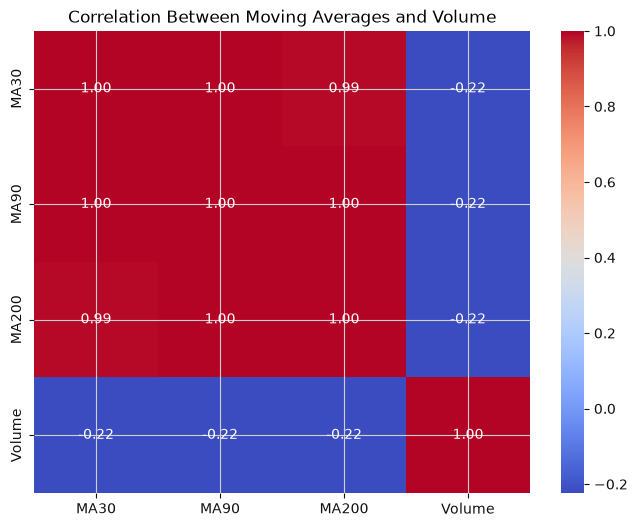

In [103]:
# Analyse correlations between moving averages of closing prices and trading volume across different time periods

# Calculate moving averages from the closing price

# 30-day moving average
# Represents the short-term trend of Apple's stock price
df['MA30'] = df['Close'].rolling(window=30).mean()

# 90-day moving average
# Represents the medium-term trend
df['MA90'] = df['Close'].rolling(window=90).mean()

# 200-day moving average
# Represents the long-term trend and is widely used
# by investors to assess market direction
df['MA200'] = df['Close'].rolling(window=200).mean()

# Calculate correlations between moving averages and volume

# Calculate Pearson correlation coefficients between
# moving averages and trading volume
corr_df = corr_data[
    ['MA30', 'MA90', 'MA200', 'Volume']
].corr()

# Display the correlation matrix
print(corr_df)

# Visualise correlations using a heatmap

# Create a figure for the heatmap
plt.figure(figsize=(8, 6))

# Plot the correlation matrix
sns.heatmap(

    # Correlation values
    corr_df,

    # Show correlation values inside each cell
    annot=True,

    # Colour scheme:
    # Red = positive correlation
    # Blue = negative correlation
    cmap='coolwarm',

    # Display values with 2 decimal places
    fmt='.2f'
)

# Add chart title
plt.title('Correlation Between Moving Averages and Volume')


The comparison of Apple's 30-day moving average and trading volume indicates that trading activity does not closely follow the long-term price trend. While the moving average exhibits substantial growth, particularly after 2010, trading volume remains comparatively volatile and does not increase at a similar rate. This suggests a relatively weak relationship between stock price trends and trading volume. Correlation analysis supports this observation, indicating that changes in Apple's long-term price trend are only weakly associated with changes in trading activity.

Interpretation of the Correlation Analysis

This analysis examines the relationship between:

MA30: 30-day moving average (short-term trend)
MA90: 90-day moving average (medium-term trend)
MA200: 200-day moving average (long-term trend)
Volume: Number of Apple shares traded

1. Extremely Strong Positive Correlation Between Moving Averages
Variables	Correlation
MA30 vs MA90	0.998
MA30 vs MA200	0.993
MA90 vs MA200	0.997

These correlation values are almost equal to 1.00, indicating a nearly perfect positive relationship.

What this means

As Apple's stock price rises:
The 30-day moving average rises.
The 90-day moving average rises.
The 200-day moving average rises.

Similarly, when the stock falls, all three moving averages decline together.

This is expected because all three moving averages are calculated from the same underlying closing-price data.

Interpretation
Apple's short-, medium-, and long-term price trends move in the same direction almost all the time. The correlation analysis confirms that the stock's long-term growth is consistently reflected across all moving-average time horizons.

2. Weak Negative Correlation Between Price Trends and Volume
Variables	Correlation
MA30 vs Volume	-0.223
MA90 vs Volume	-0.223
MA200 vs Volume	-0.223

All three moving averages have approximately the same correlation with trading volume.

What does -0.223 mean?
A correlation of -0.223 indicates:

A weak negative relationship.
The variables move somewhat independently.
There is no strong association between Apple's long-term price trend and trading activity.

Interpretation

As Apple's stock price increased over the decades:

Trading volume did not consistently increase.
In fact, volume tends to decline slightly when moving averages are higher.

However, because the correlation is only around -0.22, the relationship is weak.

3. Why Might Volume Be Negatively Correlated?

Looking at the earlier charts:
During the late 1990s and early 2000s, trading volume was extremely high.
Apple's stock price was still relatively low compared with recent years.
After 2010, the stock price increased dramatically.
Trading volume remained more stable and in some periods decreased.

This pattern produces the weak negative correlation.

Interpretation
Apple's strongest price appreciation occurred during periods when trading volume was not necessarily increasing. This suggests that long-term stock growth was driven more by increasing company value and investor confidence than by continuously rising trading activity.

4. What the Heatmap Shows
Red Areas The dark red squares indicate:
Correlation ≈ 1.0

This shows that:
MA30, MA90, MA200 all move together almost perfectly.

Blue Areas
The blue squares correspond to:
Correlation ≈ -0.22
This indicates a weak negative relationship between:
- Price trends
- Trading volume
- Financial Interpretation

The results suggest that:

✅ Apple's stock exhibits highly consistent long-term growth trends.
✅ Short-, medium-, and long-term moving averages all tell the same story.
✅ Trading volume contains information that is different from the price trend.
✅ Rising stock prices were not accompanied by proportionally higher trading volume.
✅ Long-term appreciation appears to have been driven by fundamental growth rather than simply increased trading activity.

Conclusion
The correlation analysis reveals extremely strong positive relationships among the 30-day, 90-day, and 200-day moving averages, with correlation coefficients above 0.99. This indicates that Apple's short-, medium-, and long-term price trends moved together consistently throughout the study period. In contrast, trading volume exhibits a weak negative correlation (approximately -0.22) with each moving average. This suggests that Apple's substantial long-term increase in stock price was not strongly associated with increasing trading activity. Overall, the results show that price-based trend indicators are highly aligned, while trading volume behaves relatively independently from Apple's long-term stock-price growth.

This report analysed Apple Inc. stock data from January 1981 to January 2023 using time-series analysis, descriptive statistics, hypothesis testing, correlation analysis, moving averages, and distribution modelling. The objective was to identify long-term growth patterns, assess volatility, and evaluate the statistical characteristics of Apple's stock performance.

The dataset was found to be complete, containing no missing values, and represented more than 42 years of trading-day observations. Frequency analysis confirmed that the data follows a typical stock-market structure, with gaps corresponding primarily to weekends and market holidays.

Time-series analysis revealed a strong and sustained upward trend in Apple's stock price. While prices remained relatively low during the 1980s and much of the 1990s, substantial growth emerged after 2005 and accelerated significantly after 2010. The stock reached its highest levels in 2022 before experiencing a moderate correction during 2023. Moving-average analysis (30-day, 50-day, 90-day, and 200-day averages) confirmed that this growth was consistent across short-, medium-, and long-term horizons rather than being driven by isolated price spikes.

Descriptive statistical analysis showed substantial differences between mean and median stock prices. For example, the mean closing price was $16.70, while the median closing price was only $0.49. This indicates a highly right-skewed distribution, reflecting decades of relatively low prices followed by rapid growth in recent years. The large standard deviations observed across all price variables further demonstrate significant variability and long-term appreciation throughout the study period.

Correlation analysis revealed near-perfect positive relationships among the Open, High, Low, Close, and moving-average price metrics, with correlation coefficients exceeding 0.99. This indicates that all price-based indicators move together and capture the same underlying market trend. In contrast, trading volume exhibited a weak negative correlation (approximately -0.22) with the moving averages, suggesting that Apple's long-term share-price growth was not strongly associated with increasing trading activity.

Statistical hypothesis testing provided further evidence of substantial price changes over time. Independent t-tests comparing stock prices across years consistently produced extremely small p-values, leading to the rejection of the null hypothesis in most cases. This demonstrates that average closing prices differed significantly between historical periods and confirms Apple's dramatic long-term appreciation.

Analysis of daily returns showed an average daily return of approximately 0.105%, indicating positive long-term performance. Daily return volatility was measured at 2.82%, reflecting moderate day-to-day risk typical of large technology stocks. The distribution of returns was slightly negatively skewed (-0.375) and exhibited extremely high kurtosis (18.13), indicating a greater frequency of extreme gains and losses than would be expected under a normal distribution.

Normality testing using both the Shapiro-Wilk and D'Agostino-Pearson tests strongly rejected the assumption of normally distributed returns. The return distribution displayed heavy tails and occasional extreme market movements, characteristics commonly observed in real-world financial markets.

Key Conclusions
- Apple demonstrated exceptional long-term stock-price growth between 1981 and 2023.
- Growth accelerated significantly after 2005 and particularly after 2010.
- Moving-average analysis confirmed a strong and persistent bullish trend.
- Price-based indicators are highly correlated and move together consistently.
- Trading volume shows only a weak relationship with long-term price trends.
- Most year-to-year price changes are statistically significant.
- Daily returns are positively biased but exhibit moderate volatility.
- Return distributions are non-normal, with heavy tails and elevated risk of extreme market events.

Overall, the analysis demonstrates that Apple's stock has delivered remarkable long-term value creation while exhibiting the volatility, skewness, and non-normal return behaviour that are characteristic of financial market data.

Reflection: Challenges Encountered and Solutions Implemented

Throughout this project, several technical, analytical, and statistical challenges were encountered while analysing Apple's stock data from 1981 to 2023. Addressing these challenges provided valuable experience in data preparation, time-series analysis, statistical testing, and data visualisation.

1. Date Formatting and Time-Series Preparation
One of the first challenges involved converting the Date column into a format suitable for time-series analysis. Initially, the dataset produced errors when attempting to convert dates because the records were stored in a day-first format (DD/MM/YYYY), while Pandas expected a month-first format by default.

To resolve this issue, the pd.to_datetime() function was used with the dayfirst=True parameter. After conversion, the Date column was set as the DataFrame index, allowing time-based operations such as resampling, moving averages, and trend analysis.

2. Handling Pandas Version Changes
Several compatibility issues were encountered due to updates in newer versions of Pandas. For example:
- The yearly resampling alias 'Y' generated errors and had to be replaced with 'YE'.
- Warnings were generated regarding the future deprecation of the inplace=True parameter.

These issues were resolved by modifying the syntax to align with the latest Pandas documentation and recommendations.

3. Missing Frequency Detection
When analysing the dataset's frequency, pd.infer_freq() returned None, which initially appeared to indicate a problem with the data.
Further investigation revealed that stock market data naturally contains gaps caused by weekends and public holidays, making the time series irregular. By examining the differences between consecutive dates, it became clear that the dataset followed expected trading-day behaviour.

4. Candlestick Chart Visualisation Challenges
Creating a candlestick chart for more than forty years of daily trading data proved difficult because the chart contained too many observations, making individual candlesticks impossible to interpret.
The solution was to resample the daily data into monthly intervals using Python df.resample('ME'). This reduced the number of observations and produced a much clearer visualisation of long-term market trends.

5. Correlation Analysis Challenges

Initially, NumPy's corrcoef() function generated errors because multiple arrays were supplied incorrectly. This required restructuring the input data into the appropriate matrix format.
Additionally, interpreting correlation required caution. Although the moving averages displayed near-perfect correlations, this was expected because all moving averages were derived from the same underlying closing-price data.
The analysis therefore focused on interpreting the weaker relationships between moving averages and trading volume, which provided more meaningful insights.

6. Statistical Testing Across Multiple Years

A challenge arose when performing repeated t-tests across many years. The variable storing the list of years was not initially defined, causing a NameError. 
The issue was solved by extracting unique years directly from the Date index:

Python
years = sorted(df['Year'].unique())

Beyond the coding issue, it was recognised that conducting large numbers of pairwise t-tests can increase the likelihood of false positives. To address this limitation, the analysis emphasised the broader trend of statistically significant changes across major historical periods rather than focusing solely on individual comparisons.

7. Interpreting Financial Data Distributions
Another challenge involved interpreting the descriptive statistics and normality tests.
The large differences between means and medians initially seemed unusual. However, this became understandable when considering Apple's extraordinary long-term growth. The stock traded at very low prices for many years before experiencing rapid appreciation (coinciding with the release of the iPhone), leading to highly skewed distributions.

Similarly, the very high kurtosis value and the rejection of normality by both the Shapiro-Wilk and D'Agostino-Pearson tests demonstrated that Apple stock returns do not follow a normal distribution. Understanding these statistical characteristics was essential for correctly interpreting financial data behaviour.

8. Visualisation Interpretation
While charts effectively illustrated trends, interpreting dual-axis and correlation visualisations required care. For example, volume and price movements appeared visually related at times, but statistical correlation analysis showed only a weak relationship.
Combining visual analysis with quantitative statistical testing helped avoid misleading conclusions and produced more reliable insights.

Overall Reflection
This project demonstrated the importance of combining data cleaning, exploratory analysis, statistical testing, and visualisation when analysing financial time-series data. Challenges related to date handling (especially for such a high volume of data), software version compatibility, statistical interpretation, and visualisation design were successfully addressed through careful debugging and methodological adjustments. Daily statistics had to be converted to monthly, otherwise charts were almost impossible to produce for a 40 year period. The experience highlighted that meaningful conclusions in financial analysis require both graphical inspection and rigorous statistical evidence. Ultimately, the project provided valuable insight into Apple's long-term stock performance while demonstrating the uses for Python, Pandas, NumPy, Matplotlib, Seaborn, and SciPy.